# ET-612 Statistics — Sampling Distribution of the Sample Mean

### Task
Using the `total_tch` variable:

1. Take **10,000 random samples** of a fixed size.
2. Calculate the sample mean for every sample.
3. Plot the sampling distribution.
4. Estimate the standard deviation of the sampling distribution.
5. Calculate the proportion of sample means above μ, μ + 1 SD, μ + 2 SD, and μ + 3 SD.

> **Pre-reflection is intentionally not included.**


In [115]:
# ============================================================
# 1. SETTINGS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

FILE_PATH = "integrated_Data.csv"
VARIABLE = "total_tch"

N_REPETITIONS = 10_000

# Fixed sample size
# Recommended for total_tch: 500
SAMPLE_SIZE = 500

RANDOM_SEED = 42


In [116]:
# ============================================================
# 2. LOAD AND CHECK DATA
# ============================================================

df = pd.read_csv(FILE_PATH)

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("Dataset shape:", df.shape)
print("Variable:", VARIABLE)

if VARIABLE not in df.columns:
    raise ValueError(f"Column '{VARIABLE}' was not found.")

x = pd.to_numeric(df[VARIABLE], errors="coerce")

print("Missing values:", x.isna().sum())

x = x.dropna()

population = x.to_numpy(dtype=float)
N = len(population)

if SAMPLE_SIZE <= 0:
    raise ValueError("SAMPLE_SIZE must be greater than 0.")

if SAMPLE_SIZE > N:
    raise ValueError("SAMPLE_SIZE cannot be larger than the population.")

print(f"Valid observations: {N:,}")


DATASET INFORMATION
Dataset shape: (264965, 3)
Variable: total_tch
Missing values: 0
Valid observations: 264,965


In [117]:
# ============================================================
# 3. POPULATION STATISTICS
# ============================================================

population_mean = population.mean()
population_sd = population.std(ddof=0)
population_median = np.median(population)
population_min = population.min()
population_max = population.max()

print("=" * 70)
print("POPULATION STATISTICS")
print("=" * 70)

print(f"Population size (N): {N:,}")
print(f"Population mean (μ): {population_mean:.6f}")
print(f"Population SD:       {population_sd:.6f}")
print(f"Population median:   {population_median:.6f}")
print(f"Minimum:             {population_min:.6f}")
print(f"Maximum:             {population_max:.6f}")


POPULATION STATISTICS
Population size (N): 264,965
Population mean (μ): 6.199260
Population SD:       7.415634
Population median:   5.000000
Minimum:             0.000000
Maximum:             312.000000


## 4. Generate 10,000 Random Samples

Sampling is performed **without replacement within each sample**. Each repetition produces one sample mean.


In [118]:
# ============================================================
# 4. GENERATE 10,000 RANDOM SAMPLES
# ============================================================

rng = np.random.default_rng(RANDOM_SEED)
sample_means = np.empty(N_REPETITIONS)

for i in range(N_REPETITIONS):
    sample = rng.choice(
        population,
        size=SAMPLE_SIZE,
        replace=False
    )
    sample_means[i] = sample.mean()

print(f"Generated {N_REPETITIONS:,} sample means.")
print(f"Fixed sample size: n = {SAMPLE_SIZE}")


Generated 10,000 sample means.
Fixed sample size: n = 500


In [119]:
# ============================================================
# 5. SAMPLING DISTRIBUTION STATISTICS
# ============================================================

sampling_distribution_mean = sample_means.mean()
sampling_distribution_sd = sample_means.std(ddof=1)

# Theoretical standard error with finite population correction
theoretical_se = (
    population_sd / np.sqrt(SAMPLE_SIZE)
    * np.sqrt((N - SAMPLE_SIZE) / (N - 1))
)

print("=" * 70)
print("SAMPLING DISTRIBUTION")
print("=" * 70)

print(f"Number of repetitions: {N_REPETITIONS:,}")
print(f"Sample size (n):       {SAMPLE_SIZE}")
print(f"Mean of sample means:  {sampling_distribution_mean:.6f}")
print(f"Population mean (μ):   {population_mean:.6f}")
print(f"Estimated SD of sampling distribution: {sampling_distribution_sd:.6f}")
print(f"Theoretical SE: {theoretical_se:.6f}")
print(f"Empirical SD - theoretical SE: {sampling_distribution_sd - theoretical_se:.6f}")


SAMPLING DISTRIBUTION
Number of repetitions: 10,000
Sample size (n):       500
Mean of sample means:  6.190446
Population mean (μ):   6.199260
Estimated SD of sampling distribution: 0.330233
Theoretical SE: 0.331325
Empirical SD - theoretical SE: -0.001092


In [129]:
# ============================================================
# 6. PROPORTIONS ABOVE μ, μ+1SD, μ+2SD, μ+3SD
# ============================================================

# SD refers to the SD of the sampling distribution.
# Use the SAME mean and SD throughout the analysis.

mean_sd = sampling_distribution_mean
sd = sampling_distribution_sd

total = len(sample_means)

# ------------------------------------------------------------
# Thresholds
# ------------------------------------------------------------

thresholds = {
    "μ": mean_sd,
    "μ + 1 SD": mean_sd + sd,
    "μ + 2 SD": mean_sd + 2 * sd,
    "μ + 3 SD": mean_sd + 3 * sd
}

# ------------------------------------------------------------
# Calculate empirical results
# ------------------------------------------------------------

results = []

for label, threshold in thresholds.items():

    count_above = np.sum(sample_means > threshold)

    proportion_above = count_above / total

    percentage_above = proportion_above * 100

    results.append({
        "Threshold": label,
        "Threshold Value": threshold,
        "Number Above": count_above,
        "Proportion Above": proportion_above,
        "Percentage Above": percentage_above
    })

results_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Display empirical results
# ------------------------------------------------------------

print("=" * 80)
print("PROPORTION OF SAMPLE MEANS ABOVE THRESHOLDS")
print("=" * 80)

display(
    results_df.style.format({
        "Threshold Value": "{:.6f}",
        "Number Above": "{:,}",
        "Proportion Above": "{:.6f}",
        "Percentage Above": "{:.3f}%"
    })
)


# ============================================================
# 7. EMPIRICAL VS NORMAL EXPECTATION
# ============================================================

# ------------------------------------------------------------
# Theoretical normal right-tail percentages
# ------------------------------------------------------------

normal_reference = {
    "μ": 50.000,
    "μ + 1 SD": 15.866,
    "μ + 2 SD": 2.275,
    "μ + 3 SD": 0.135
}

# ------------------------------------------------------------
# Create comparison table FROM results_df
# ------------------------------------------------------------

comparison_df = results_df[
    [
        "Threshold",
        "Threshold Value",
        "Number Above",
        "Percentage Above"
    ]
].copy()

# Add normal expectation
comparison_df["Normal Expected (%)"] = (
    comparison_df["Threshold"]
    .map(normal_reference)
)

# ------------------------------------------------------------
# Difference from normal
# ------------------------------------------------------------

comparison_df["Difference (percentage points)"] = (
    comparison_df["Percentage Above"]
    - comparison_df["Normal Expected (%)"]
)

# ------------------------------------------------------------
# Display comparison
# ------------------------------------------------------------

print("=" * 90)
print("EMPIRICAL VS NORMAL EXPECTATION")
print("=" * 90)

display(
    comparison_df.style.format({
        "Threshold Value": "{:.6f}",
        "Number Above": "{:,}",
        "Percentage Above": "{:.3f}%",
        "Normal Expected (%)": "{:.3f}%",
        "Difference (percentage points)": "{:+.3f}"
    })
)

PROPORTION OF SAMPLE MEANS ABOVE THRESHOLDS


,Threshold,Threshold Value,Number Above,Proportion Above,Percentage Above
0,μ,6.190446,"4,663",0.466300,46.630%
1,μ + 1 SD,6.520678,"1,575",0.157500,15.750%
2,μ + 2 SD,6.850911,342,0.034200,3.420%
3,μ + 3 SD,7.181143,51,0.005100,0.510%


EMPIRICAL VS NORMAL EXPECTATION


,Threshold,Threshold Value,Number Above,Percentage Above,Normal Expected (%),Difference (percentage points)
0,μ,6.190446,"4,663",46.630%,50.000%,-3.370
1,μ + 1 SD,6.520678,"1,575",15.750%,15.866%,-0.116
2,μ + 2 SD,6.850911,342,3.420%,2.275%,+1.145
3,μ + 3 SD,7.181143,51,0.510%,0.135%,+0.375


In [121]:
# ============================================================
# 7. EMPIRICAL VS NORMAL EXPECTATION
#    USE THE SAME CALCULATIONS AS THE PLOT
# ============================================================

# ------------------------------------------------------------
# Current sampling distribution parameters
# ------------------------------------------------------------

mean_sd = sampling_distribution_mean
sd = sampling_distribution_sd

# ------------------------------------------------------------
# Thresholds
# ------------------------------------------------------------

threshold_0 = mean_sd
threshold_1 = mean_sd + sd
threshold_2 = mean_sd + 2 * sd
threshold_3 = mean_sd + 3 * sd

# ------------------------------------------------------------
# Calculate counts directly from CURRENT sample_means
# ------------------------------------------------------------

total = len(sample_means)

count_0 = np.sum(sample_means > threshold_0)
count_1 = np.sum(sample_means > threshold_1)
count_2 = np.sum(sample_means > threshold_2)
count_3 = np.sum(sample_means > threshold_3)

# ------------------------------------------------------------
# Calculate percentages
# ------------------------------------------------------------

pct_0 = count_0 / total * 100
pct_1 = count_1 / total * 100
pct_2 = count_2 / total * 100
pct_3 = count_3 / total * 100

# ------------------------------------------------------------
# Normal theoretical right-tail percentages
# ------------------------------------------------------------

normal_reference = {
    "μ": 50.000,
    "μ + 1 SD": 15.866,
    "μ + 2 SD": 2.275,
    "μ + 3 SD": 0.135
}

# ------------------------------------------------------------
# Create NEW comparison table
# ------------------------------------------------------------

comparison_df = pd.DataFrame({
    "Threshold": [
        "μ",
        "μ + 1 SD",
        "μ + 2 SD",
        "μ + 3 SD"
    ],

    "Percentage Above": [
        pct_0,
        pct_1,
        pct_2,
        pct_3
    ],

    "Normal Expected (%)": [
        normal_reference["μ"],
        normal_reference["μ + 1 SD"],
        normal_reference["μ + 2 SD"],
        normal_reference["μ + 3 SD"]
    ]
})

# ------------------------------------------------------------
# Difference from normal
# ------------------------------------------------------------

comparison_df["Difference (percentage points)"] = (
    comparison_df["Percentage Above"]
    - comparison_df["Normal Expected (%)"]
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 70)
print("EMPIRICAL VS NORMAL EXPECTATION")
print("=" * 70)

display(
    comparison_df.style.format({
        "Percentage Above": "{:.3f}%",
        "Normal Expected (%)": "{:.3f}%",
        "Difference (percentage points)": "{:+.3f}"
    })
)

EMPIRICAL VS NORMAL EXPECTATION


,Threshold,Percentage Above,Normal Expected (%),Difference (percentage points)
0,μ,46.630%,50.000%,-3.370
1,μ + 1 SD,15.750%,15.866%,-0.116
2,μ + 2 SD,3.420%,2.275%,+1.145
3,μ + 3 SD,0.510%,0.135%,+0.375


In [122]:
# ============================================================
# 8. CHECK CENTRE AND SHAPE
# ============================================================

difference_in_means = sampling_distribution_mean - population_mean
sampling_skewness = stats.skew(sample_means)
sampling_kurtosis = stats.kurtosis(sample_means)

print("=" * 70)
print("CENTRE AND SHAPE")
print("=" * 70)

print(f"Population mean:        {population_mean:.6f}")
print(f"Mean of sample means:   {sampling_distribution_mean:.6f}")
print(f"Difference:              {difference_in_means:.6f}")
print(f"Sampling skewness:       {sampling_skewness:.6f}")
print(f"Excess kurtosis:         {sampling_kurtosis:.6f}")


CENTRE AND SHAPE
Population mean:        6.199260
Mean of sample means:   6.190446
Difference:              -0.008815
Sampling skewness:       0.447557
Excess kurtosis:         0.247839


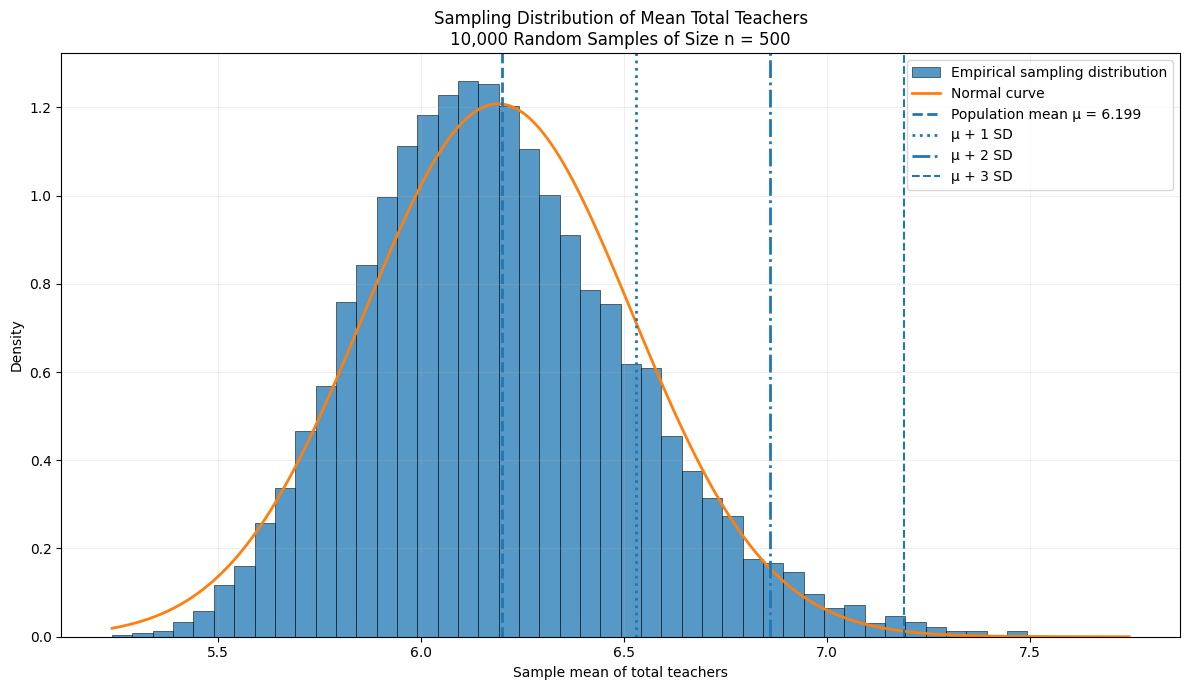

In [123]:
# ============================================================
# 9. PLOT SAMPLING DISTRIBUTION
# ============================================================

plt.figure(figsize=(12, 7))

plt.hist(
    sample_means,
    bins=50,
    density=True,
    alpha=0.75,
    edgecolor="black",
    linewidth=0.5,
    label="Empirical sampling distribution"
)

x_axis = np.linspace(
    sample_means.min(),
    sample_means.max(),
    500
)

normal_curve = stats.norm.pdf(
    x_axis,
    loc=sampling_distribution_mean,
    scale=sampling_distribution_sd
)

plt.plot(
    x_axis,
    normal_curve,
    linewidth=2,
    label="Normal curve"
)

plt.axvline(
    population_mean,
    linestyle="--",
    linewidth=2,
    label=f"Population mean μ = {population_mean:.3f}"
)

plt.axvline(
    population_mean + sampling_distribution_sd,
    linestyle=":",
    linewidth=2,
    label="μ + 1 SD"
)

plt.axvline(
    population_mean + 2 * sampling_distribution_sd,
    linestyle="-.",
    linewidth=2,
    label="μ + 2 SD"
)

plt.axvline(
    population_mean + 3 * sampling_distribution_sd,
    linestyle="--",
    linewidth=1.5,
    label="μ + 3 SD"
)

plt.title(
    "Sampling Distribution of Mean Total Teachers\n"
    f"{N_REPETITIONS:,} Random Samples of Size n = {SAMPLE_SIZE}"
)

plt.xlabel("Sample mean of total teachers")
plt.ylabel("Density")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "sampling_distribution_total_tch.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


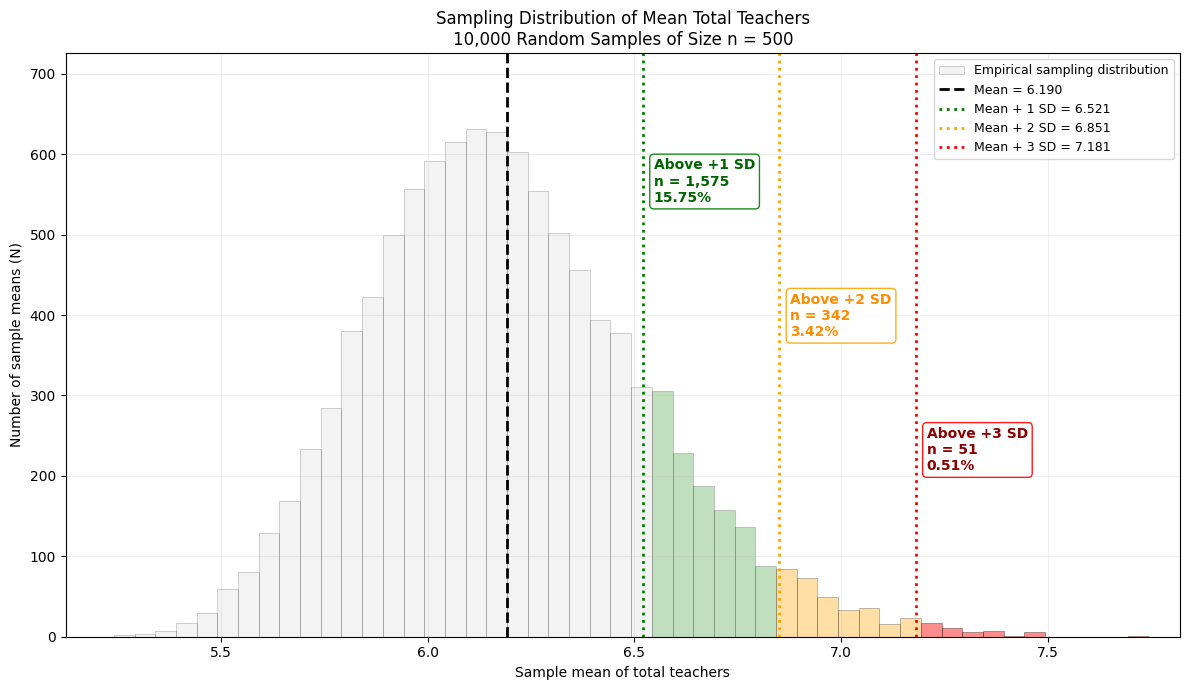

SAMPLE MEANS ABOVE SD THRESHOLDS
Above +1 SD: 1,575 / 10,000 (15.75%)
Above +2 SD: 342 / 10,000 (3.42%)
Above +3 SD: 51 / 10,000 (0.51%)


In [124]:
# ============================================================
# 9. PLOT SAMPLING DISTRIBUTION WITH POSITIVE SD REGIONS
#    ACTUAL NUMBER OF SAMPLE MEANS (N)
#    NO NORMAL CURVE
#    BIN-CENTER COLORING
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

# ------------------------------------------------------------
# Calculate thresholds
# ------------------------------------------------------------

mean_sd = sampling_distribution_mean
sd = sampling_distribution_sd

threshold_1 = mean_sd + sd
threshold_2 = mean_sd + 2 * sd
threshold_3 = mean_sd + 3 * sd

# ------------------------------------------------------------
# SAME X-AXIS SCALE AS NEGATIVE SD PLOT
# ------------------------------------------------------------

x_min = min(
    sample_means.min(),
    mean_sd - 3 * sd
)

x_max = sample_means.max()

margin = (x_max - x_min) * 0.03

x_min -= margin
x_max += margin

# ------------------------------------------------------------
# Histogram — ACTUAL COUNTS
# ------------------------------------------------------------

counts, bins, patches = plt.hist(
    sample_means,
    bins=50,
    density=False,
    alpha=0.25,
    edgecolor="black",
    linewidth=0.5,
    label="Empirical sampling distribution"
)

# ------------------------------------------------------------
# COLOR HISTOGRAM BARS USING BIN CENTER
# ------------------------------------------------------------

for patch, left, right in zip(
    patches,
    bins[:-1],
    bins[1:]
):

    # Center of the histogram bin
    bin_center = (left + right) / 2

    # --------------------------------------------------------
    # Above +3 SD
    # --------------------------------------------------------
    if bin_center >= threshold_3:

        patch.set_facecolor("red")
        patch.set_alpha(0.45)

    # --------------------------------------------------------
    # Between +2 SD and +3 SD
    # --------------------------------------------------------
    elif bin_center >= threshold_2:

        patch.set_facecolor("orange")
        patch.set_alpha(0.35)

    # --------------------------------------------------------
    # Between +1 SD and +2 SD
    # --------------------------------------------------------
    elif bin_center >= threshold_1:

        patch.set_facecolor("green")
        patch.set_alpha(0.25)

    # --------------------------------------------------------
    # Everything at or below +1 SD
    # --------------------------------------------------------
    else:

        patch.set_facecolor("lightgray")
        patch.set_alpha(0.25)

# ------------------------------------------------------------
# Mean
# ------------------------------------------------------------

plt.axvline(
    mean_sd,
    linestyle="--",
    linewidth=2,
    color="black",
    label=f"Mean = {mean_sd:.3f}"
)

# ------------------------------------------------------------
# Positive SD lines
# ------------------------------------------------------------

plt.axvline(
    threshold_1,
    linestyle=":",
    linewidth=2,
    color="green",
    label=f"Mean + 1 SD = {threshold_1:.3f}"
)

plt.axvline(
    threshold_2,
    linestyle=":",
    linewidth=2,
    color="orange",
    label=f"Mean + 2 SD = {threshold_2:.3f}"
)

plt.axvline(
    threshold_3,
    linestyle=":",
    linewidth=2,
    color="red",
    label=f"Mean + 3 SD = {threshold_3:.3f}"
)

# ------------------------------------------------------------
# COUNTS ABOVE EACH THRESHOLD
# ------------------------------------------------------------

count_1 = np.sum(sample_means > threshold_1)
count_2 = np.sum(sample_means > threshold_2)
count_3 = np.sum(sample_means > threshold_3)

total = len(sample_means)

pct_1 = count_1 / total * 100
pct_2 = count_2 / total * 100
pct_3 = count_3 / total * 100

# ------------------------------------------------------------
# Y-AXIS — ACTUAL N
# ------------------------------------------------------------

y_limit = counts.max() * 1.15

plt.ylim(
    0,
    y_limit
)

# ------------------------------------------------------------
# ANNOTATIONS
# ------------------------------------------------------------

offset = 0.08 * sd

# ------------------------------------------------------------
# +1 SD
# ------------------------------------------------------------

plt.text(
    threshold_1 + offset,
    y_limit * 0.78,

    f"Above +1 SD\n"
    f"n = {count_1:,}\n"
    f"{pct_1:.2f}%",

    ha="left",
    va="center",

    fontsize=10,
    color="darkgreen",
    fontweight="bold",

    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="green",
        alpha=0.90
    )
)

# ------------------------------------------------------------
# +2 SD
# ------------------------------------------------------------

plt.text(
    threshold_2 + offset,
    y_limit * 0.55,

    f"Above +2 SD\n"
    f"n = {count_2:,}\n"
    f"{pct_2:.2f}%",

    ha="left",
    va="center",

    fontsize=10,
    color="darkorange",
    fontweight="bold",

    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="orange",
        alpha=0.90
    )
)

# ------------------------------------------------------------
# +3 SD
# ------------------------------------------------------------

plt.text(
    threshold_3 + offset,
    y_limit * 0.32,

    f"Above +3 SD\n"
    f"n = {count_3:,}\n"
    f"{pct_3:.2f}%",

    ha="left",
    va="center",

    fontsize=10,
    color="darkred",
    fontweight="bold",

    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="red",
        alpha=0.90
    )
)

# ------------------------------------------------------------
# FORCE SAME X-AXIS SCALE
# ------------------------------------------------------------

plt.xlim(
    x_min,
    x_max
)

# ------------------------------------------------------------
# Labels and formatting
# ------------------------------------------------------------

plt.title(
    "Sampling Distribution of Mean Total Teachers\n"
    f"{N_REPETITIONS:,} Random Samples of Size n = {SAMPLE_SIZE}"
)

plt.xlabel(
    "Sample mean of total teachers"
)

plt.ylabel(
    "Number of sample means (N)"
)

plt.legend(
    loc="upper right",
    fontsize=9
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.savefig(
    "sampling_distribution_total_tch_positive_SD_counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# PRINT RESULTS
# ============================================================

print("=" * 60)
print("SAMPLE MEANS ABOVE SD THRESHOLDS")
print("=" * 60)

print(
    f"Above +1 SD: {count_1:,} / {total:,} "
    f"({pct_1:.2f}%)"
)

print(
    f"Above +2 SD: {count_2:,} / {total:,} "
    f"({pct_2:.2f}%)"
)

print(
    f"Above +3 SD: {count_3:,} / {total:,} "
    f"({pct_3:.2f}%)"
)

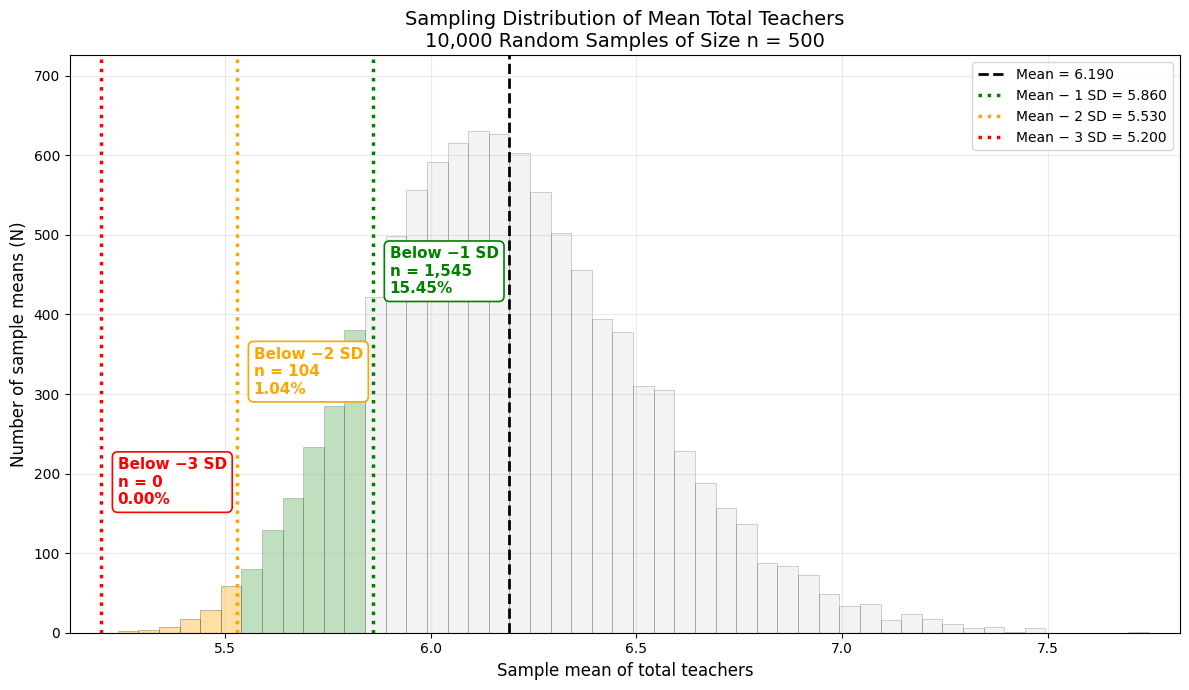

In [125]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Parameters
# --------------------------------------------------
mean_sd = sampling_distribution_mean
sd = sampling_distribution_sd

threshold_minus_1 = mean_sd - sd
threshold_minus_2 = mean_sd - 2 * sd
threshold_minus_3 = mean_sd - 3 * sd

# --------------------------------------------------
# Counts
# --------------------------------------------------
total = len(sample_means)

count_minus_1 = np.sum(sample_means < threshold_minus_1)
count_minus_2 = np.sum(sample_means < threshold_minus_2)
count_minus_3 = np.sum(sample_means < threshold_minus_3)

pct_minus_1 = count_minus_1 / total * 100
pct_minus_2 = count_minus_2 / total * 100
pct_minus_3 = count_minus_3 / total * 100

# --------------------------------------------------
# Histogram
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 7))

counts, bins, patches = ax.hist(
    sample_means,
    bins=50,
    density=False,
    alpha=0.25,
    edgecolor="black",
    linewidth=0.5
)

# --------------------------------------------------
# Color histogram bars using BIN CENTRE
# --------------------------------------------------

for patch, left, right in zip(
    patches,
    bins[:-1],
    bins[1:]
):

    # Center of the current histogram bin
    bin_center = (left + right) / 2

    # ------------------------------------------------
    # Below -3 SD
    # ------------------------------------------------
    if bin_center < threshold_minus_3:

        patch.set_facecolor("red")
        patch.set_alpha(0.45)

    # ------------------------------------------------
    # Between -3 SD and -2 SD
    # ------------------------------------------------
    elif bin_center < threshold_minus_2:

        patch.set_facecolor("orange")
        patch.set_alpha(0.35)

    # ------------------------------------------------
    # Between -2 SD and -1 SD
    # ------------------------------------------------
    elif bin_center < threshold_minus_1:

        patch.set_facecolor("green")
        patch.set_alpha(0.25)

    # ------------------------------------------------
    # Everything else — normal distribution region
    # ------------------------------------------------
    else:

        patch.set_facecolor("lightgray")
        patch.set_alpha(0.25)

# --------------------------------------------------
# Mean and SD lines
# --------------------------------------------------

ax.axvline(
    mean_sd,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_sd:.3f}"
)

ax.axvline(
    threshold_minus_1,
    color="green",
    linestyle=":",
    linewidth=2.5,
    label=f"Mean − 1 SD = {threshold_minus_1:.3f}"
)

ax.axvline(
    threshold_minus_2,
    color="orange",
    linestyle=":",
    linewidth=2.5,
    label=f"Mean − 2 SD = {threshold_minus_2:.3f}"
)

ax.axvline(
    threshold_minus_3,
    color="red",
    linestyle=":",
    linewidth=2.5,
    label=f"Mean − 3 SD = {threshold_minus_3:.3f}"
)

# --------------------------------------------------
# Y-axis
# --------------------------------------------------

y_max = counts.max()

ax.set_ylim(
    0,
    y_max * 1.15
)

# --------------------------------------------------
# ANNOTATIONS
# --------------------------------------------------

# -1 SD
ax.annotate(
    f"Below −1 SD\n"
    f"n = {count_minus_1:,}\n"
    f"{pct_minus_1:.2f}%",

    xy=(threshold_minus_1, y_max * 0.72),
    xytext=(12, 0),
    textcoords="offset points",

    ha="left",
    va="center",

    fontsize=11,
    fontweight="bold",
    color="green",

    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="green",
        linewidth=1.2
    )
)

# -2 SD
ax.annotate(
    f"Below −2 SD\n"
    f"n = {count_minus_2:,}\n"
    f"{pct_minus_2:.2f}%",

    xy=(threshold_minus_2, y_max * 0.52),
    xytext=(12, 0),
    textcoords="offset points",

    ha="left",
    va="center",

    fontsize=11,
    fontweight="bold",
    color="orange",

    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="orange",
        linewidth=1.2
    )
)

# -3 SD
ax.annotate(
    f"Below −3 SD\n"
    f"n = {count_minus_3:,}\n"
    f"{pct_minus_3:.2f}%",

    xy=(threshold_minus_3, y_max * 0.30),
    xytext=(12, 0),
    textcoords="offset points",

    ha="left",
    va="center",

    fontsize=11,
    fontweight="bold",
    color="red",

    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="red",
        linewidth=1.2
    )
)

# --------------------------------------------------
# X-axis limits
# --------------------------------------------------

x_min = min(
    sample_means.min(),
    threshold_minus_3
)

x_max = sample_means.max()

x_range = x_max - x_min

ax.set_xlim(
    x_min - 0.03 * x_range,
    x_max + 0.03 * x_range
)

# --------------------------------------------------
# Labels
# --------------------------------------------------

ax.set_xlabel(
    "Sample mean of total teachers",
    fontsize=12
)

ax.set_ylabel(
    "Number of sample means (N)",
    fontsize=12
)

ax.set_title(
    "Sampling Distribution of Mean Total Teachers\n"
    f"{total:,} Random Samples of Size n = {SAMPLE_SIZE}",
    fontsize=14
)

ax.legend(
    loc="upper right"
)

ax.grid(
    axis="both",
    alpha=0.25
)

plt.tight_layout()
plt.show()

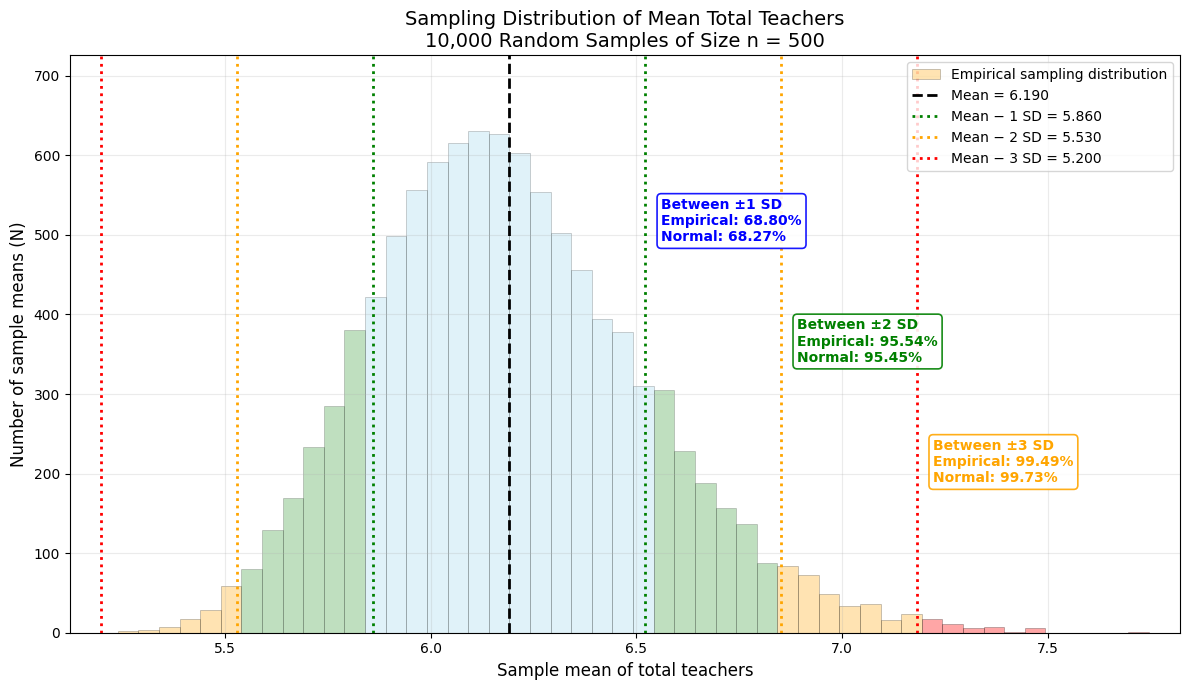

In [126]:
# ============================================================
# 10. SAMPLING DISTRIBUTION: ±1, ±2, ±3 SD
#    MATCHED HISTOGRAM + ANNOTATION COLORS
# ============================================================

plt.figure(figsize=(12, 7))

mean_sd = sampling_distribution_mean
sd = sampling_distribution_sd

minus_1 = mean_sd - sd
plus_1  = mean_sd + sd

minus_2 = mean_sd - 2 * sd
plus_2  = mean_sd + 2 * sd

minus_3 = mean_sd - 3 * sd
plus_3  = mean_sd + 3 * sd

# ------------------------------------------------------------
# X-axis scale
# ------------------------------------------------------------

x_min = min(sample_means.min(), minus_3)
x_max = max(sample_means.max(), plus_3)

margin = (x_max - x_min) * 0.03

x_min -= margin
x_max += margin

# ------------------------------------------------------------
# Histogram — ACTUAL COUNTS
# ------------------------------------------------------------

counts, bins, patches = plt.hist(
    sample_means,
    bins=50,
    density=False,
    alpha=0.25,
    edgecolor="black",
    linewidth=0.5,
    label="Empirical sampling distribution"
)

# ------------------------------------------------------------
# COLOR HISTOGRAM BARS USING BIN CENTER
#
# Central ±1 SD  → SKYBLUE
# ±1 to ±2 SD    → GREEN
# ±2 to ±3 SD    → ORANGE
# Beyond ±3 SD   → RED
# ------------------------------------------------------------

for patch, left, right in zip(
    patches,
    bins[:-1],
    bins[1:]
):

    bin_center = (left + right) / 2

    distance_from_mean = abs(bin_center - mean_sd)

    # Central ±1 SD
    if distance_from_mean <= sd:

        patch.set_facecolor("skyblue")
        patch.set_alpha(0.25)

    # ±1 to ±2 SD
    elif distance_from_mean <= 2 * sd:

        patch.set_facecolor("green")
        patch.set_alpha(0.25)

    # ±2 to ±3 SD
    elif distance_from_mean <= 3 * sd:

        patch.set_facecolor("orange")
        patch.set_alpha(0.30)

    # Beyond ±3 SD
    else:

        patch.set_facecolor("red")
        patch.set_alpha(0.35)

# ------------------------------------------------------------
# EMPIRICAL PERCENTAGES
# ------------------------------------------------------------

total = len(sample_means)

within_1 = np.sum(
    (sample_means >= minus_1) &
    (sample_means <= plus_1)
)

within_2 = np.sum(
    (sample_means >= minus_2) &
    (sample_means <= plus_2)
)

within_3 = np.sum(
    (sample_means >= minus_3) &
    (sample_means <= plus_3)
)

pct_1 = within_1 / total * 100
pct_2 = within_2 / total * 100
pct_3 = within_3 / total * 100

# ------------------------------------------------------------
# THEORETICAL NORMAL PERCENTAGES
# ------------------------------------------------------------

theoretical_1 = 68.27
theoretical_2 = 95.45
theoretical_3 = 99.73

# ------------------------------------------------------------
# MEAN
# ------------------------------------------------------------

plt.axvline(
    mean_sd,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_sd:.3f}"
)

# ------------------------------------------------------------
# SD LINES
# ------------------------------------------------------------

for value, color, label in [

    (minus_1, "green", f"Mean − 1 SD = {minus_1:.3f}"),
    (plus_1,  "green", None),

    (minus_2, "orange", f"Mean − 2 SD = {minus_2:.3f}"),
    (plus_2,  "orange", None),

    (minus_3, "red", f"Mean − 3 SD = {minus_3:.3f}"),
    (plus_3,  "red", None)

]:

    plt.axvline(
        value,
        color=color,
        linestyle=":",
        linewidth=2,
        label=label
    )

# ------------------------------------------------------------
# ANNOTATION HEIGHT
# ------------------------------------------------------------

y_max = counts.max()

# ------------------------------------------------------------
# ±1 SD ANNOTATION — BLUE
# ------------------------------------------------------------

plt.text(
    plus_1 + 0.12 * sd,
    y_max * 0.82,

    f"Between ±1 SD\n"
    f"Empirical: {pct_1:.2f}%\n"
    f"Normal: {theoretical_1:.2f}%",

    ha="left",
    va="center",

    fontsize=10,
    fontweight="bold",

    color="blue",

    bbox=dict(
        boxstyle="round,pad=0.30",
        facecolor="white",
        edgecolor="blue",
        linewidth=1.2,
        alpha=0.90
    )
)

# ------------------------------------------------------------
# ±2 SD ANNOTATION — GREEN
# ------------------------------------------------------------

plt.text(
    plus_2 + 0.12 * sd,
    y_max * 0.58,

    f"Between ±2 SD\n"
    f"Empirical: {pct_2:.2f}%\n"
    f"Normal: {theoretical_2:.2f}%",

    ha="left",
    va="center",

    fontsize=10,
    fontweight="bold",

    color="green",

    bbox=dict(
        boxstyle="round,pad=0.30",
        facecolor="white",
        edgecolor="green",
        linewidth=1.2,
        alpha=0.90
    )
)

# ------------------------------------------------------------
# ±3 SD ANNOTATION — ORANGE
# ------------------------------------------------------------

plt.text(
    plus_3 + 0.12 * sd,
    y_max * 0.34,

    f"Between ±3 SD\n"
    f"Empirical: {pct_3:.2f}%\n"
    f"Normal: {theoretical_3:.2f}%",

    ha="left",
    va="center",

    fontsize=10,
    fontweight="bold",

    color="orange",

    bbox=dict(
        boxstyle="round,pad=0.30",
        facecolor="white",
        edgecolor="orange",
        linewidth=1.2,
        alpha=0.90
    )
)

# ------------------------------------------------------------
# Y-AXIS
# ------------------------------------------------------------

plt.ylim(
    0,
    y_max * 1.15
)

plt.ylabel(
    "Number of sample means (N)",
    fontsize=12
)

# ------------------------------------------------------------
# X-AXIS
# ------------------------------------------------------------

plt.xlim(
    x_min,
    x_max
)

plt.xlabel(
    "Sample mean of total teachers",
    fontsize=12
)

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

plt.title(
    "Sampling Distribution of Mean Total Teachers\n"
    f"{total:,} Random Samples of Size n = {SAMPLE_SIZE}",
    fontsize=14
)

# ------------------------------------------------------------
# LEGEND
# ------------------------------------------------------------

plt.legend(
    loc="upper right"
)

plt.grid(
    axis="both",
    alpha=0.25
)

plt.tight_layout()

plt.show()

In [127]:
# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("=" * 70)
print("FINAL SUMMARY")
print("=" * 70)

print(f"Variable: {VARIABLE}")
print()
print(f"Population size: N = {N:,}")
print(f"Population mean (μ) = {population_mean:.4f}")
print(f"Population SD = {population_sd:.4f}")
print()
print(f"Number of repetitions = {N_REPETITIONS:,}")
print(f"Sample size = {SAMPLE_SIZE}")
print()
print(f"Mean of sample means = {sampling_distribution_mean:.4f}")
print(f"Estimated SD of sampling distribution = {sampling_distribution_sd:.4f}")
print(f"Theoretical SE = {theoretical_se:.4f}")
print()
print("The empirical proportions above μ, μ+1SD, μ+2SD and μ+3SD")
print("are shown above and can be compared with normal-distribution")
print("reference values.")


FINAL SUMMARY
Variable: total_tch

Population size: N = 264,965
Population mean (μ) = 6.1993
Population SD = 7.4156

Number of repetitions = 10,000
Sample size = 500

Mean of sample means = 6.1904
Estimated SD of sampling distribution = 0.3302
Theoretical SE = 0.3313

The empirical proportions above μ, μ+1SD, μ+2SD and μ+3SD
are shown above and can be compared with normal-distribution
reference values.


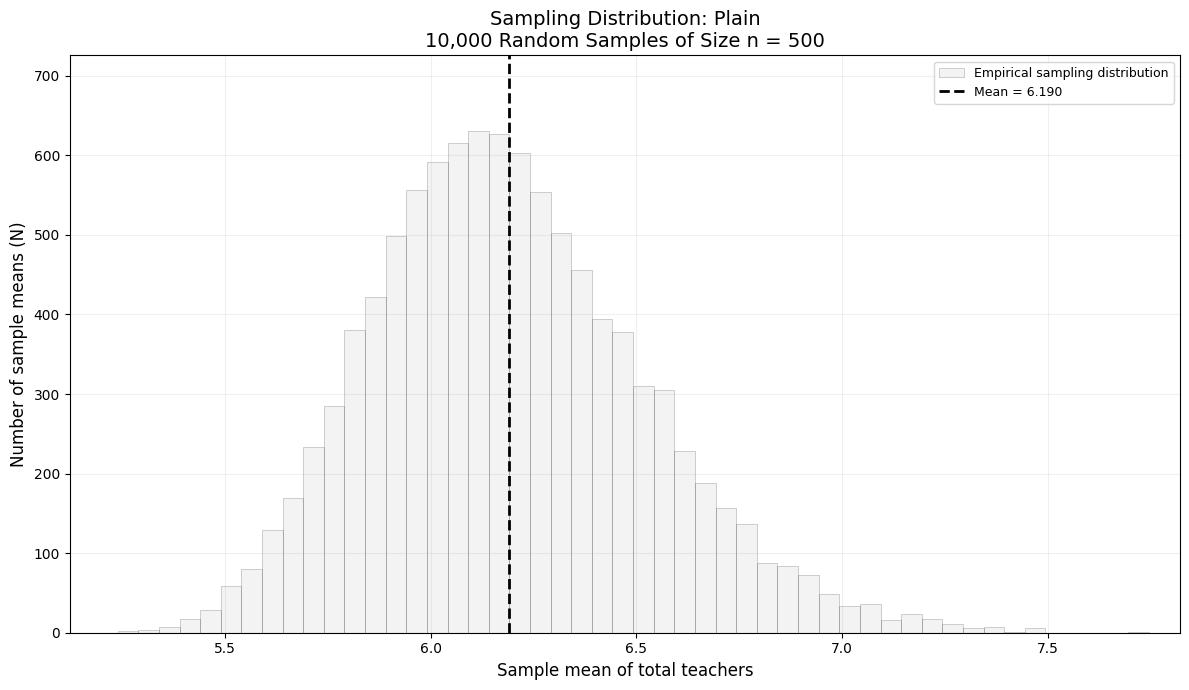

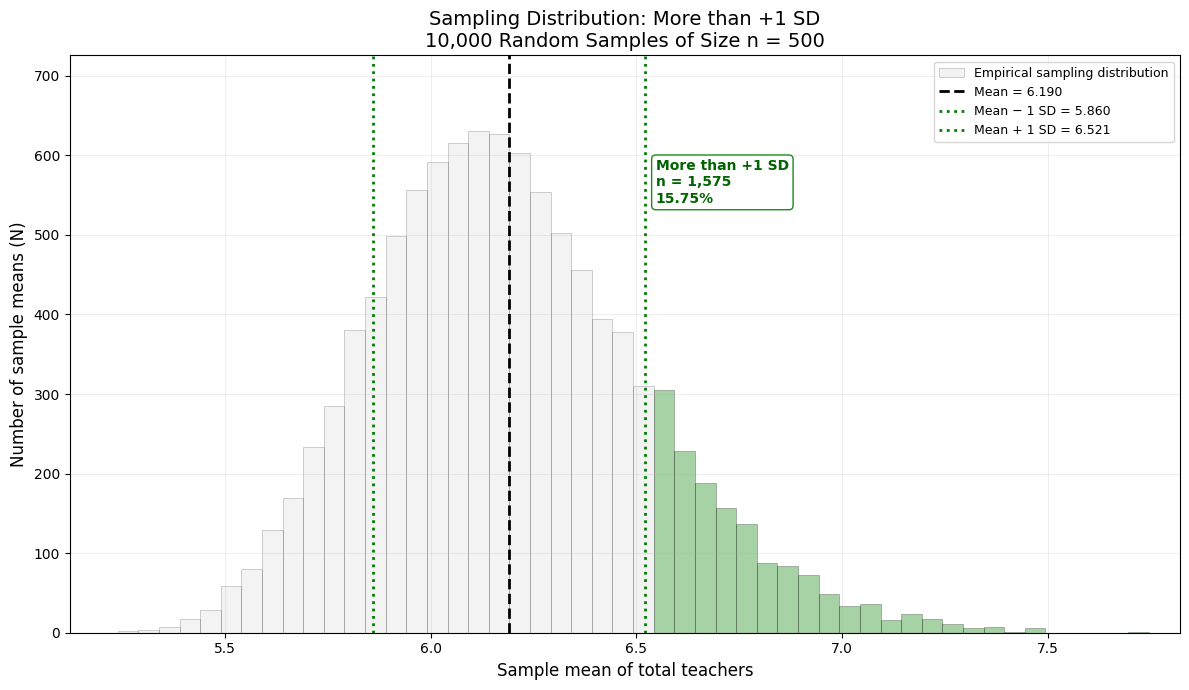

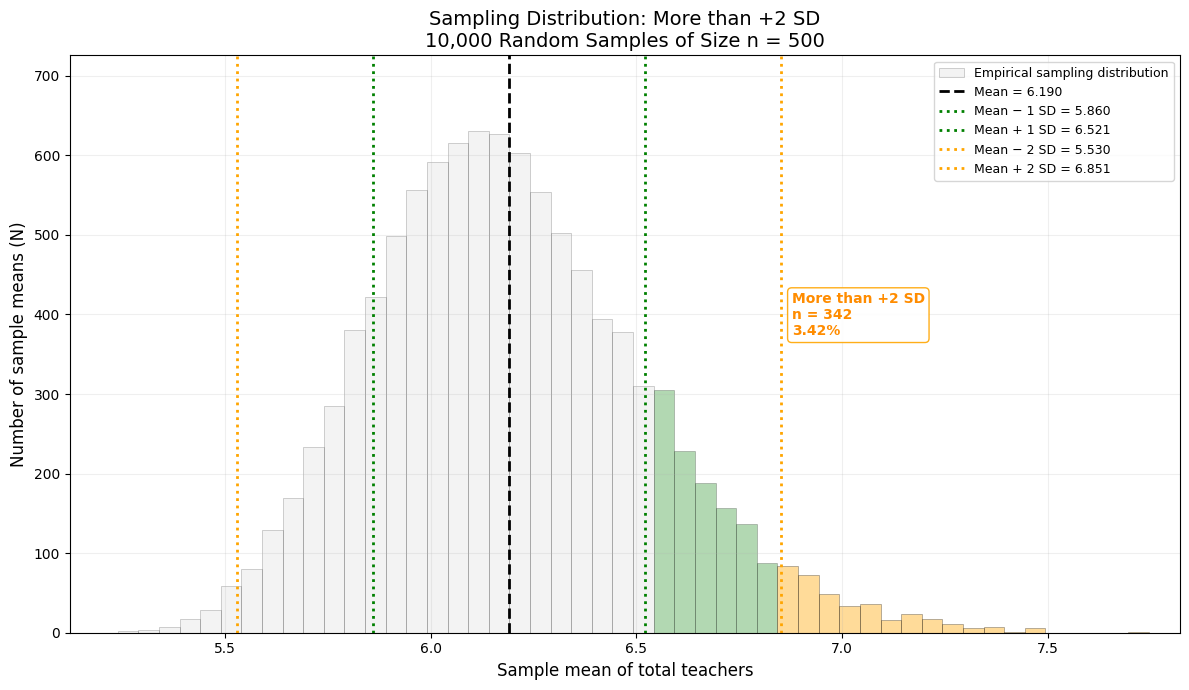

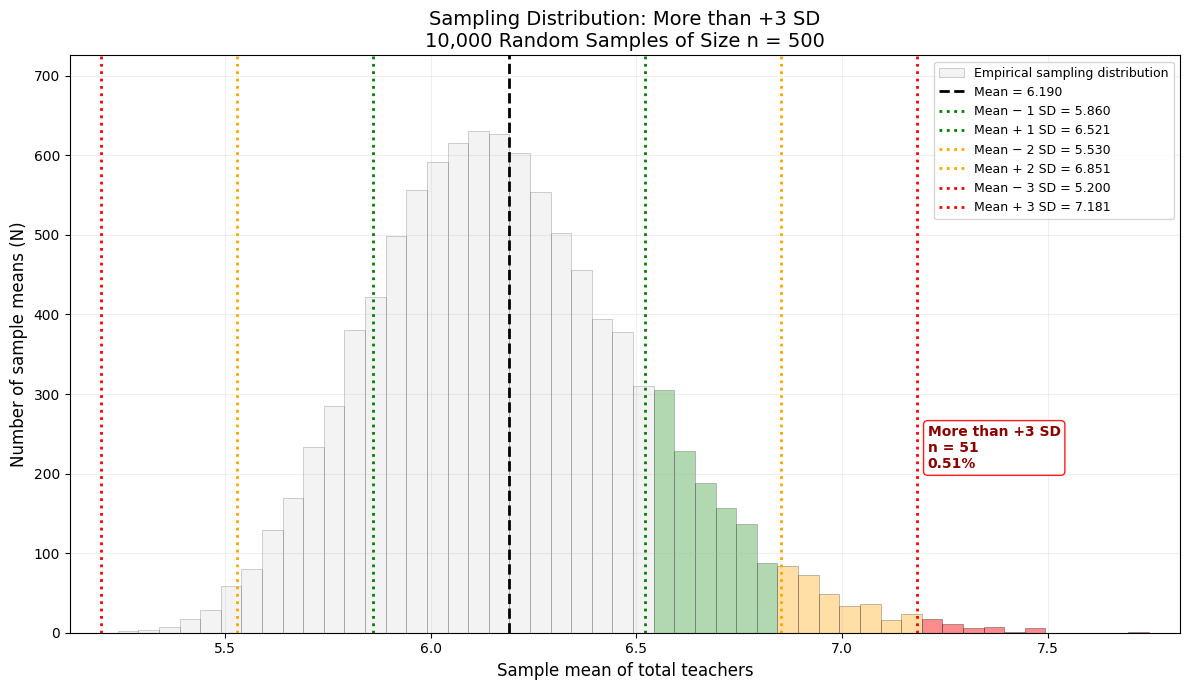

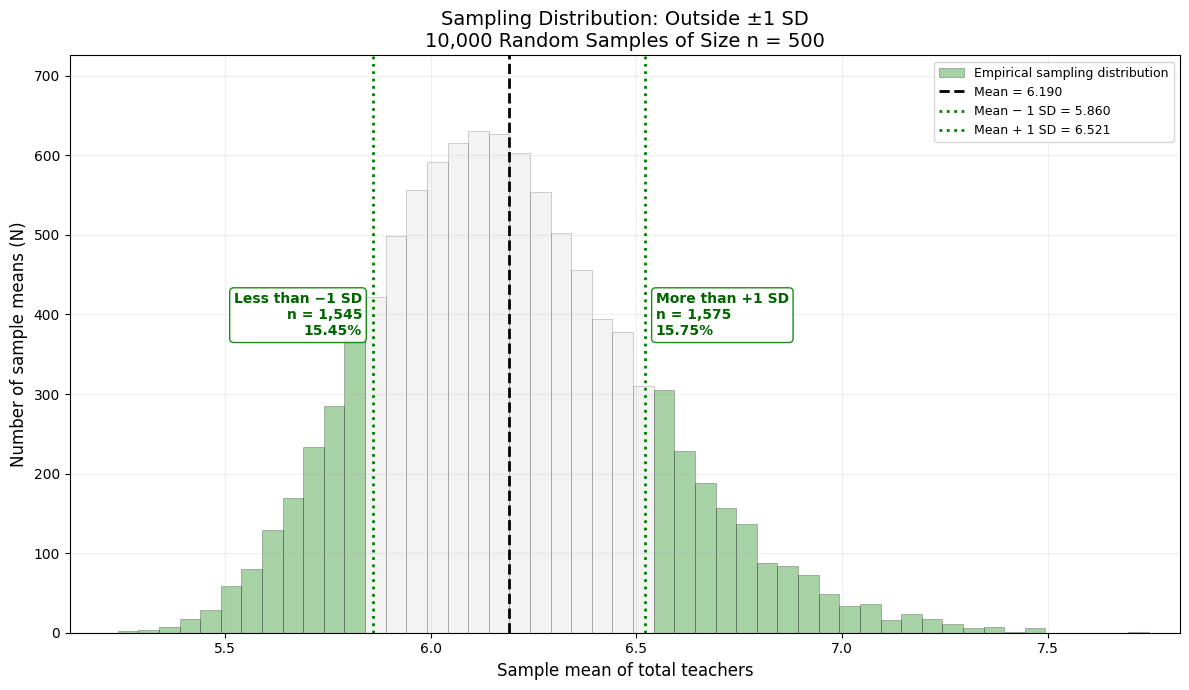

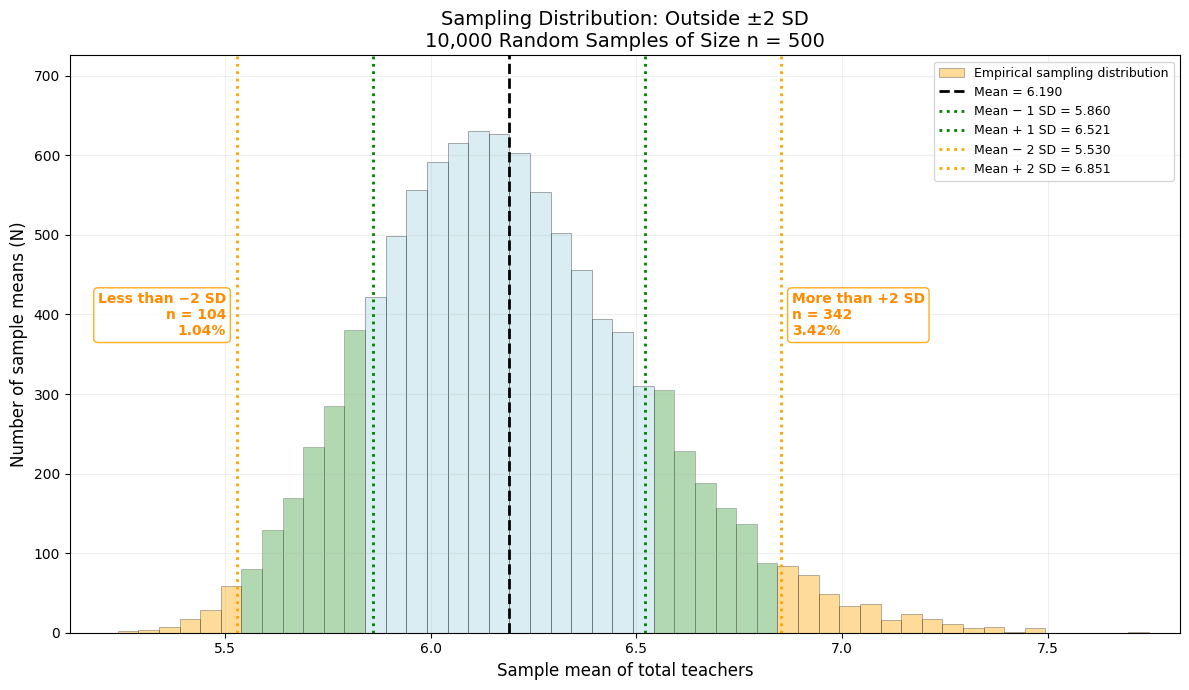

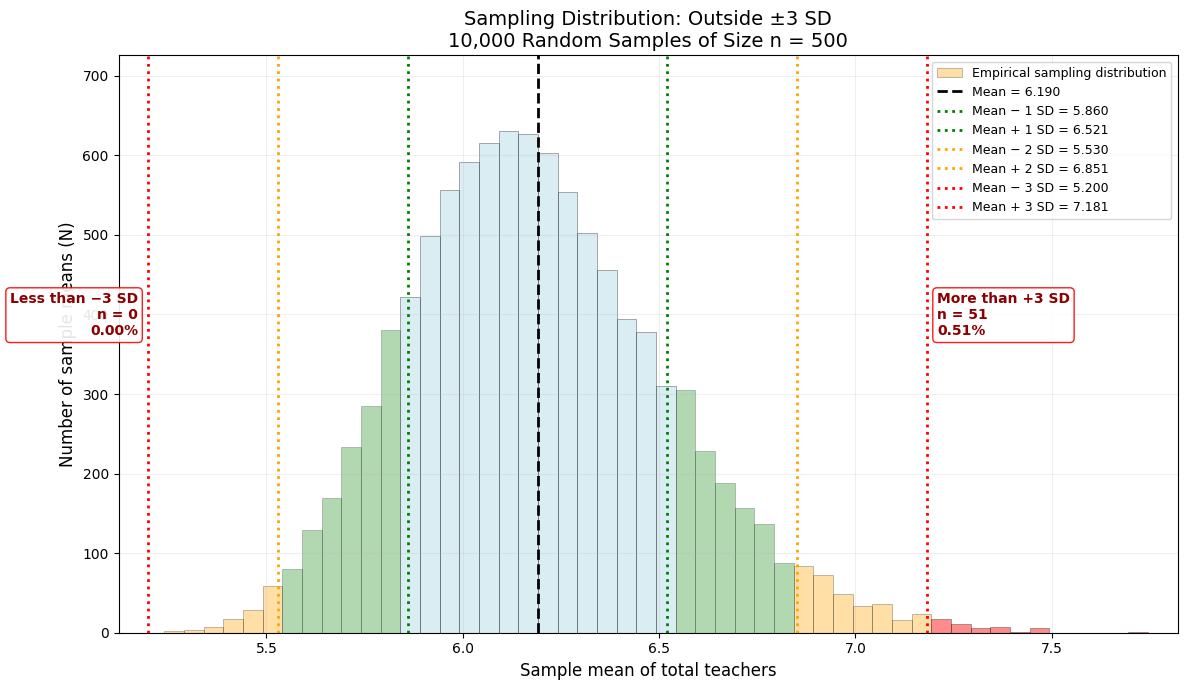

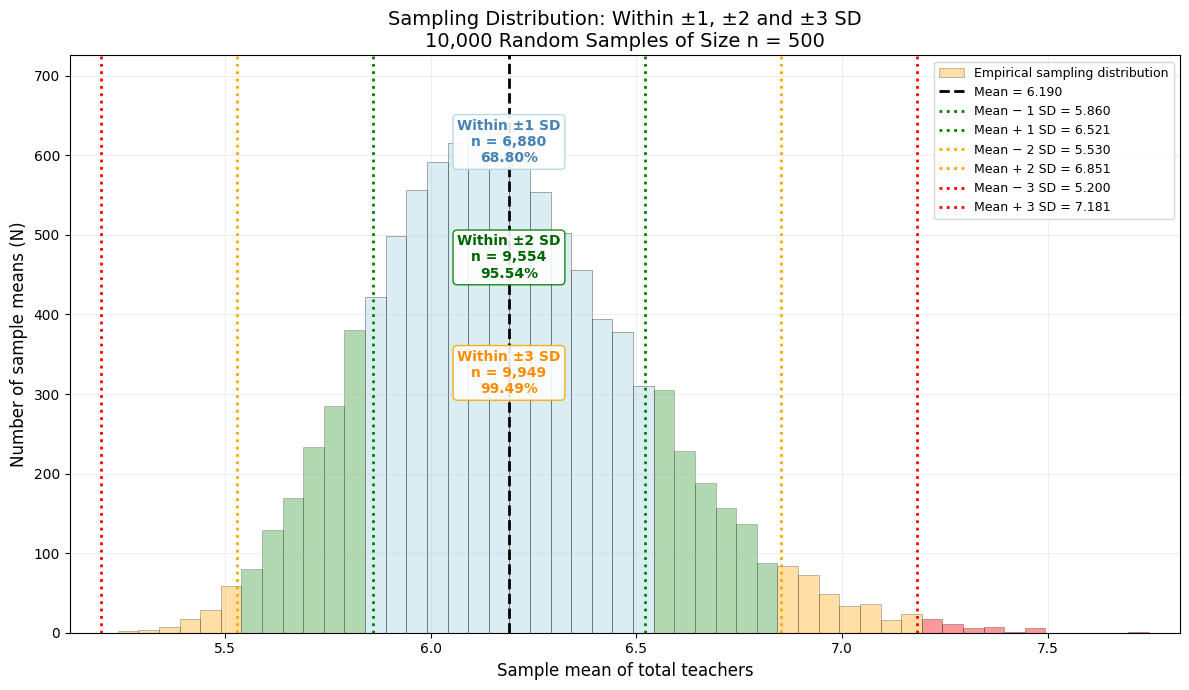

In [ ]:
# ============================================================
# SAMPLING DISTRIBUTION — ALL FIGURES FOR ANIMATION
#
# 1. More than +1 SD
# 2. More than +2 SD
# 3. More than +3 SD
# 4. Outside ±1 SD
# 5. Outside ±2 SD
# 6. Outside ±3 SD
# 7. Complete ±1, ±2, ±3 SD
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# PARAMETERS
# ============================================================

mean_sd = sampling_distribution_mean
sd = sampling_distribution_sd
total = len(sample_means)

minus_1 = mean_sd - sd
plus_1  = mean_sd + sd

minus_2 = mean_sd - 2 * sd
plus_2  = mean_sd + 2 * sd

minus_3 = mean_sd - 3 * sd
plus_3  = mean_sd + 3 * sd


# ============================================================
# FIXED BINS AND AXIS LIMITS
# ============================================================

bins = np.histogram_bin_edges(
    sample_means,
    bins=50
)

counts, _ = np.histogram(
    sample_means,
    bins=bins
)

y_max = counts.max()
y_limit = y_max * 1.15

x_min = min(
    sample_means.min(),
    minus_3
)

x_max = max(
    sample_means.max(),
    plus_3
)

margin = (x_max - x_min) * 0.03

x_min -= margin
x_max += margin


# ============================================================
# COMMON PLOT FUNCTION
# ============================================================

def plot_sampling_distribution(
    title,
    more_than_1=False,
    more_than_2=False,
    more_than_3=False,
    outside_1=False,
    outside_2=False,
    outside_3=False,
    complete=False
):

    fig, ax = plt.subplots(figsize=(12, 7))

    # --------------------------------------------------------
    # HISTOGRAM
    # --------------------------------------------------------

    counts_plot, bins_plot, patches = ax.hist(
        sample_means,
        bins=bins,
        density=False,
        alpha=0.25,
        edgecolor="black",
        linewidth=0.5,
        label="Empirical sampling distribution"
    )


    # --------------------------------------------------------
    # COLOR HISTOGRAM
    # --------------------------------------------------------

    for patch, left, right in zip(
        patches,
        bins_plot[:-1],
        bins_plot[1:]
    ):

        bin_center = (left + right) / 2

        # Default
        patch.set_facecolor("lightgray")
        patch.set_alpha(0.25)


        # ====================================================
        # FIGURE 7 — COMPLETE
        # ====================================================

        if complete:

            distance = abs(bin_center - mean_sd)

            # Within ±1 SD
            if distance <= sd:

                patch.set_facecolor("lightblue")
                patch.set_alpha(0.45)

            # Between ±1 and ±2 SD
            elif distance <= 2 * sd:

                patch.set_facecolor("green")
                patch.set_alpha(0.30)

            # Between ±2 and ±3 SD
            elif distance <= 3 * sd:

                patch.set_facecolor("orange")
                patch.set_alpha(0.35)

            # Beyond ±3 SD
            else:

                patch.set_facecolor("red")
                patch.set_alpha(0.40)


        # ====================================================
        # FIGURE 6 — OUTSIDE ±3 SD
        # KEEP ±1 AND ±2 REGIONS
        # ====================================================

        elif outside_3:

            distance = abs(bin_center - mean_sd)

            if distance <= sd:

                # Within ±1
                patch.set_facecolor("lightblue")
                patch.set_alpha(0.45)

            elif distance <= 2 * sd:

                # ±1 to ±2
                patch.set_facecolor("green")
                patch.set_alpha(0.30)

            elif distance <= 3 * sd:

                # ±2 to ±3
                patch.set_facecolor("orange")
                patch.set_alpha(0.35)

            else:

                # Beyond ±3
                patch.set_facecolor("red")
                patch.set_alpha(0.45)


        # ====================================================
        # FIGURE 5 — OUTSIDE ±2 SD
        # KEEP ±1 REGION
        # ====================================================

        elif outside_2:

            distance = abs(bin_center - mean_sd)

            if distance <= sd:

                # Within ±1
                patch.set_facecolor("lightblue")
                patch.set_alpha(0.45)

            elif distance <= 2 * sd:

                # Between ±1 and ±2
                patch.set_facecolor("green")
                patch.set_alpha(0.30)

            else:

                # Beyond ±2
                patch.set_facecolor("orange")
                patch.set_alpha(0.40)


        # ====================================================
        # FIGURE 4 — OUTSIDE ±1 SD
        # ====================================================

        elif outside_1:

            distance = abs(bin_center - mean_sd)

            if distance <= sd:

                # Inside ±1 remains gray
                patch.set_facecolor("lightgray")
                patch.set_alpha(0.25)

            else:

                # Outside ±1
                patch.set_facecolor("green")
                patch.set_alpha(0.35)


        # ====================================================
        # FIGURE 3 — MORE THAN +3 SD
        # KEEP +1 AND +2
        # ====================================================

        elif more_than_3:

            if bin_center >= plus_3:

                # > +3
                patch.set_facecolor("red")
                patch.set_alpha(0.45)

            elif bin_center >= plus_2:

                # +2 to +3
                patch.set_facecolor("orange")
                patch.set_alpha(0.35)

            elif bin_center >= plus_1:

                # +1 to +2
                patch.set_facecolor("green")
                patch.set_alpha(0.30)


        # ====================================================
        # FIGURE 2 — MORE THAN +2 SD
        # KEEP +1 REGION
        # ====================================================

        elif more_than_2:

            if bin_center >= plus_2:

                # > +2
                patch.set_facecolor("orange")
                patch.set_alpha(0.40)

            elif bin_center >= plus_1:

                # +1 to +2
                patch.set_facecolor("green")
                patch.set_alpha(0.30)


        # ====================================================
        # FIGURE 1 — MORE THAN +1 SD
        # ====================================================

        elif more_than_1:

            if bin_center >= plus_1:

                patch.set_facecolor("green")
                patch.set_alpha(0.35)


    # ========================================================
    # MEAN
    # ========================================================

    ax.axvline(
        mean_sd,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Mean = {mean_sd:.3f}"
    )


    # ========================================================
    # SD LINES
    # ========================================================

    if (
        more_than_1 or
        more_than_2 or
        more_than_3 or
        outside_1 or
        outside_2 or
        outside_3 or
        complete
    ):

        ax.axvline(
            minus_1,
            color="green",
            linestyle=":",
            linewidth=2,
            label=f"Mean − 1 SD = {minus_1:.3f}"
        )

        ax.axvline(
            plus_1,
            color="green",
            linestyle=":",
            linewidth=2,
            label=f"Mean + 1 SD = {plus_1:.3f}"
        )


    if (
        more_than_2 or
        more_than_3 or
        outside_2 or
        outside_3 or
        complete
    ):

        ax.axvline(
            minus_2,
            color="orange",
            linestyle=":",
            linewidth=2,
            label=f"Mean − 2 SD = {minus_2:.3f}"
        )

        ax.axvline(
            plus_2,
            color="orange",
            linestyle=":",
            linewidth=2,
            label=f"Mean + 2 SD = {plus_2:.3f}"
        )


    if (
        more_than_3 or
        outside_3 or
        complete
    ):

        ax.axvline(
            minus_3,
            color="red",
            linestyle=":",
            linewidth=2,
            label=f"Mean − 3 SD = {minus_3:.3f}"
        )

        ax.axvline(
            plus_3,
            color="red",
            linestyle=":",
            linewidth=2,
            label=f"Mean + 3 SD = {plus_3:.3f}"
        )


    # ========================================================
    # COUNTS
    # ========================================================

    count_minus_1 = np.sum(sample_means < minus_1)
    count_plus_1  = np.sum(sample_means > plus_1)

    count_minus_2 = np.sum(sample_means < minus_2)
    count_plus_2  = np.sum(sample_means > plus_2)

    count_minus_3 = np.sum(sample_means < minus_3)
    count_plus_3  = np.sum(sample_means > plus_3)


    # ========================================================
    # MORE THAN +1
    # ========================================================

    if more_than_1:

        ax.text(
            plus_1 + 0.08 * sd,
            y_limit * 0.78,
            f"More than +1 SD\n"
            f"n = {count_plus_1:,}\n"
            f"{count_plus_1 / total * 100:.2f}%",
            ha="left",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="darkgreen",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="green",
                alpha=0.90
            )
        )


    # ========================================================
    # MORE THAN +2
    # ========================================================

    if more_than_2:

        ax.text(
            plus_2 + 0.08 * sd,
            y_limit * 0.55,
            f"More than +2 SD\n"
            f"n = {count_plus_2:,}\n"
            f"{count_plus_2 / total * 100:.2f}%",
            ha="left",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="darkorange",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="orange",
                alpha=0.90
            )
        )


    # ========================================================
    # MORE THAN +3
    # ========================================================

    if more_than_3:

        ax.text(
            plus_3 + 0.08 * sd,
            y_limit * 0.32,
            f"More than +3 SD\n"
            f"n = {count_plus_3:,}\n"
            f"{count_plus_3 / total * 100:.2f}%",
            ha="left",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="darkred",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="red",
                alpha=0.90
            )
        )


    # ========================================================
    # OUTSIDE ±1
    # SEPARATE LEFT AND RIGHT
    # ========================================================

    if outside_1:

        ax.text(
            minus_1 - 0.08 * sd,
            y_limit * 0.55,
            f"Less than −1 SD\n"
            f"n = {count_minus_1:,}\n"
            f"{count_minus_1 / total * 100:.2f}%",
            ha="right",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="darkgreen",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="green",
                alpha=0.90
            )
        )

        ax.text(
            plus_1 + 0.08 * sd,
            y_limit * 0.55,
            f"More than +1 SD\n"
            f"n = {count_plus_1:,}\n"
            f"{count_plus_1 / total * 100:.2f}%",
            ha="left",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="darkgreen",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="green",
                alpha=0.90
            )
        )


    # ========================================================
    # OUTSIDE ±2
    # ========================================================

    if outside_2:

        ax.text(
            minus_2 - 0.08 * sd,
            y_limit * 0.55,
            f"Less than −2 SD\n"
            f"n = {count_minus_2:,}\n"
            f"{count_minus_2 / total * 100:.2f}%",
            ha="right",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="darkorange",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="orange",
                alpha=0.90
            )
        )

        ax.text(
            plus_2 + 0.08 * sd,
            y_limit * 0.55,
            f"More than +2 SD\n"
            f"n = {count_plus_2:,}\n"
            f"{count_plus_2 / total * 100:.2f}%",
            ha="left",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="darkorange",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="orange",
                alpha=0.90
            )
        )


    # ========================================================
    # OUTSIDE ±3
    # ========================================================

    # ========================================================
# OUTSIDE ±3
# KEEP ANNOTATIONS INSIDE THE GRAPH
# ========================================================

    if outside_3:

        # ----------------------------------------------------
        # LEFT: Less than −3 SD
        # ----------------------------------------------------

        ax.text(
            minus_3 + 0.05 * sd,
            y_limit * 0.55,
            f"Less than −3 SD\n"
            f"n = {count_minus_3:,}\n"
            f"{count_minus_3 / total * 100:.2f}%",
            ha="left",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="darkred",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="red",
                alpha=0.90
            )
        )

        # ----------------------------------------------------
        # RIGHT: More than +3 SD
        # ----------------------------------------------------

        ax.text(
            plus_3 - 0.05 * sd,
            y_limit * 0.55,
            f"More than +3 SD\n"
            f"n = {count_plus_3:,}\n"
            f"{count_plus_3 / total * 100:.2f}%",
            ha="right",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="darkred",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="red",
                alpha=0.90
            )
        )

    # ========================================================
    # COMPLETE FIGURE
    # ========================================================

    if complete:

        within_1 = np.sum(
            (sample_means >= minus_1) &
            (sample_means <= plus_1)
        )

        within_2 = np.sum(
            (sample_means >= minus_2) &
            (sample_means <= plus_2)
        )

        within_3 = np.sum(
            (sample_means >= minus_3) &
            (sample_means <= plus_3)
        )

        ax.text(
            mean_sd,
            y_limit * 0.85,
            f"Within ±1 SD\n"
            f"n = {within_1:,}\n"
            f"{within_1 / total * 100:.2f}%",
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="steelblue",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="lightblue",
                alpha=0.90
            )
        )

        ax.text(
            mean_sd,
            y_limit * 0.65,
            f"Within ±2 SD\n"
            f"n = {within_2:,}\n"
            f"{within_2 / total * 100:.2f}%",
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="darkgreen",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="green",
                alpha=0.90
            )
        )

        ax.text(
            mean_sd,
            y_limit * 0.45,
            f"Within ±3 SD\n"
            f"n = {within_3:,}\n"
            f"{within_3 / total * 100:.2f}%",
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="darkorange",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="orange",
                alpha=0.90
            )
        )


    # ========================================================
    # AXES
    # ========================================================

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(0, y_limit)

    ax.set_xlabel(
        "Sample mean of total teachers",
        fontsize=12
    )

    ax.set_ylabel(
        "Number of sample means (N)",
        fontsize=12
    )

    ax.set_title(
        f"{title}\n"
        f"{total:,} Random Samples of Size n = {SAMPLE_SIZE}",
        fontsize=14
    )

    ax.legend(
        loc="upper right",
        fontsize=9
    )

    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

# ============================================================
# FIGURE 0 — PLAIN SAMPLING DISTRIBUTION
# NO HIGHLIGHTS OR SD LINES
# ============================================================

plot_sampling_distribution(
    "Sampling Distribution: Plain",
)


# ============================================================
# FIGURE 1 — MORE THAN +1 SD
# ============================================================

plot_sampling_distribution(
    "Sampling Distribution: More than +1 SD",
    more_than_1=True
)


# ============================================================
# FIGURE 2 — MORE THAN +2 SD
# +1 SD REGION REMAINS
# ============================================================

plot_sampling_distribution(
    "Sampling Distribution: More than +2 SD",
    more_than_2=True
)


# ============================================================
# FIGURE 3 — MORE THAN +3 SD
# +1 AND +2 SD REGIONS REMAIN
# ============================================================

plot_sampling_distribution(
    "Sampling Distribution: More than +3 SD",
    more_than_3=True
)


# ============================================================
# FIGURE 4 — OUTSIDE ±1 SD
# ============================================================

plot_sampling_distribution(
    "Sampling Distribution: Outside ±1 SD",
    outside_1=True
)


# ============================================================
# FIGURE 5 — OUTSIDE ±2 SD
# ±1 AND ±2 REGIONS REMAIN
# ============================================================

plot_sampling_distribution(
    "Sampling Distribution: Outside ±2 SD",
    outside_2=True
)


# ============================================================
# FIGURE 6 — OUTSIDE ±3 SD
# ALL THREE LEVELS REMAIN
# ============================================================

plot_sampling_distribution(
    "Sampling Distribution: Outside ±3 SD",
    outside_3=True
)


# ============================================================
# FIGURE 7 — COMPLETE ±1, ±2, ±3 SD
# ============================================================

plot_sampling_distribution(
    "Sampling Distribution: Within ±1, ±2 and ±3 SD",
    complete=True
)

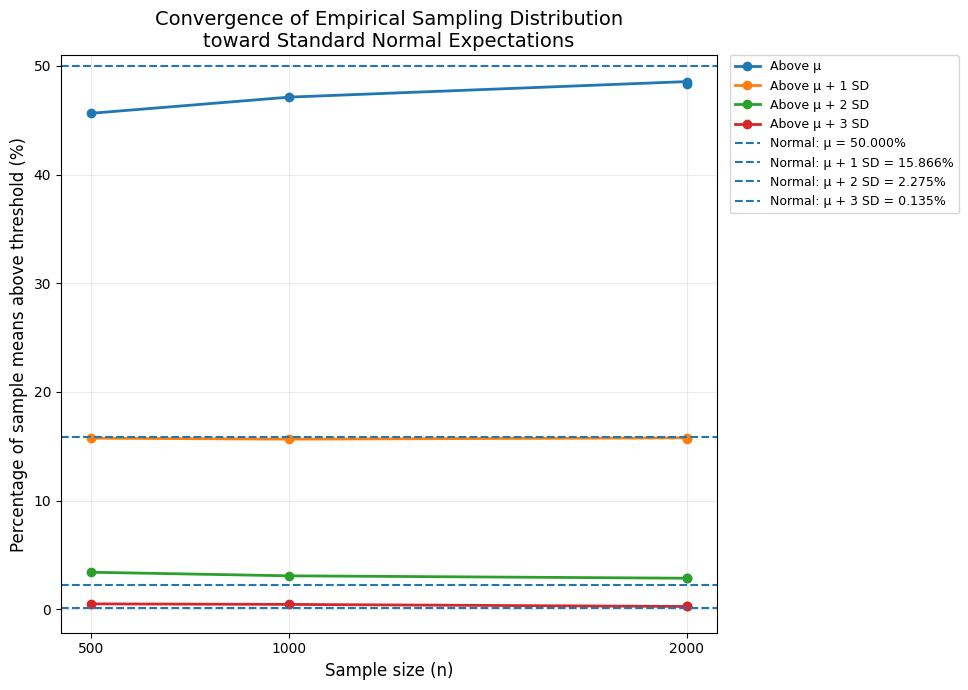

In [131]:
# ============================================================
# PLOT: CONVERGENCE OF EMPIRICAL PROPORTIONS TO NORMAL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Data from the table
# ------------------------------------------------------------

sample_sizes = [500, 1000, 2000, 2000]

# Empirical percentages
above_mean = [45.630, 47.120, 48.550, 48.340]
above_1sd  = [15.750, 15.660, 15.780, 15.720]
above_2sd  = [3.420, 3.090, 2.870, 2.870]
above_3sd  = [0.510, 0.460, 0.270, 0.290]

# Normal theoretical expectations
normal_mean = 50.000
normal_1sd  = 15.866
normal_2sd  = 2.275
normal_3sd  = 0.135

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

# ------------------------------------------------------------
# Empirical lines
# ------------------------------------------------------------

plt.plot(
    sample_sizes,
    above_mean,
    marker="o",
    linewidth=2,
    label="Above μ"
)

plt.plot(
    sample_sizes,
    above_1sd,
    marker="o",
    linewidth=2,
    label="Above μ + 1 SD"
)

plt.plot(
    sample_sizes,
    above_2sd,
    marker="o",
    linewidth=2,
    label="Above μ + 2 SD"
)

plt.plot(
    sample_sizes,
    above_3sd,
    marker="o",
    linewidth=2,
    label="Above μ + 3 SD"
)

# ------------------------------------------------------------
# Normal expected reference lines
# ------------------------------------------------------------

plt.axhline(
    normal_mean,
    linestyle="--",
    linewidth=1.5,
    label="Normal: μ = 50.000%"
)

plt.axhline(
    normal_1sd,
    linestyle="--",
    linewidth=1.5,
    label="Normal: μ + 1 SD = 15.866%"
)

plt.axhline(
    normal_2sd,
    linestyle="--",
    linewidth=1.5,
    label="Normal: μ + 2 SD = 2.275%"
)

plt.axhline(
    normal_3sd,
    linestyle="--",
    linewidth=1.5,
    label="Normal: μ + 3 SD = 0.135%"
)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

plt.xlabel(
    "Sample size (n)",
    fontsize=12
)

plt.ylabel(
    "Percentage of sample means above threshold (%)",
    fontsize=12
)

plt.title(
    "Convergence of Empirical Sampling Distribution\n"
    "toward Standard Normal Expectations",
    fontsize=14
)

# ------------------------------------------------------------
# X-axis
# ------------------------------------------------------------

plt.xticks(
    [500, 1000, 2000]
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

plt.grid(
    alpha=0.25
)

# ------------------------------------------------------------
# Legend — OUTSIDE the graph
# ------------------------------------------------------------

plt.legend(
    fontsize=9,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)

# Leave space on the right for the legend
plt.tight_layout(rect=[0, 0, 0.82, 1])

plt.show()